# Reproducible KDSource runs with `kds_runs`

This notebook demonstrates the high-level `brightify.kds_runs` API:

- create or load a reproducible run,
- fit a KDSource model from an MCPL file,
- resample particles from the fitted model,
- compare generated particles with reference MCPL data,
- inspect persisted stage information and plot comparison metrics.

The paths in this notebook are relative to the Brightify repository root.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from brightify.kds_runs import Run, compare_runs
from brightify.data_augmentation import read_df_from_mcpl

plt.rcParams["figure.dpi"] = 110

## 1. Locate the example data

`resampled.mcpl.gz` is used as the input for fitting and `uniform/output.mcpl.gz` is available as a separate comparison reference.

In [2]:
ROOT = Path.cwd()
INPUT_MCPL = ROOT / "examples" / "resampled.mcpl.gz"
UNIFORM_MCPL = ROOT / "examples" / "uniform" / "output.mcpl.gz"
RUN_DIR = ROOT / "runs" / "kds_runs_showcase"

for path in (INPUT_MCPL, UNIFORM_MCPL):
    print(path, "exists:", path.is_file(), "size:", path.stat().st_size if path.is_file() else "missing")

/home/jhonal/Brightify/examples/resampled.mcpl.gz exists: True size: 50639378
/home/jhonal/Brightify/examples/uniform/output.mcpl.gz exists: True size: 480756300


## 2. Create or load a run

`Run` writes a `run.json` manifest in its dedicated directory. The helper below makes the notebook safe to re-open: it loads the existing run when the manifest is present, instead of trying to create a directory that already contains `run.json`.

In [3]:
manifest = RUN_DIR / "run.json"

if manifest.exists():
    run = Run.load(manifest)
    print("Loaded existing run:", run.id)
else:
    run = Run(
        input_mcpl=INPUT_MCPL,
        run_dir=RUN_DIR,
        name="kds-runs-resampled-showcase",
        fit_parameters={
            "N": 10_000,
            "bw": "knn",
            "J": 1,
            "kernel": "gaussian",
        },
    )
    print("Created run:", run.id)

run.to_dict()

Created run: e4fa1fb09b8744d8b9658435055b2eae


{'metadata_version': 1,
 'id': 'e4fa1fb09b8744d8b9658435055b2eae',
 'name': 'kds-runs-resampled-showcase',
 'created_at': '2026-11-23T17:19:02.098312+00:00',
 'input_mcpl': {'path': '/home/jhonal/Brightify/examples/resampled.mcpl.gz',
  'size_bytes': 50639378,
  'modified_ns': 1795020206195988917},
 'run_dir': '/home/jhonal/Brightify/runs/kds_runs_showcase',
 'fit_parameters': {'N': 10000, 'bw': 'knn', 'J': 1, 'kernel': 'gaussian'},
 'resample_parameters': {},
 'result': {'status': 'pending',
  'model_path': None,
  'bws_path': None,
  'generated_mcpl': None,
  'stages': {},
  'timings': {},
  'comparisons': []}}

## 3. Fit the KDSource model

`fit()` forwards the fit parameters to `brightify.data_augmentation.fit()`, records timing and success/failure information in the manifest, and saves `model.xml` inside the run directory.

In [4]:
if not run.model_path.is_file():
    model_path, bws_path = run.fit()
else:
    model_path, bws_path = run.model_path, run.bws_path

print("Model:", model_path)
print("Bandwidths:", bws_path)
print("Status:", run.status)

bw_kwargs that were accepted are: {}
Using existing file /home/jhonal/Brightify/examples/resampled.mcpl.gz
sum_weights = 2000000.0
p2 = 2000000.0
N = 2000000
N_eff = 2000000.0
[<kdsource.geom.Lethargy object at 0x7e7d8584be00>, <kdsource.geom.SurfXY object at 0x7e7dd114caa0>, <kdsource.geom.PolarMu object at 0x7e7dd12bc290>, <kdsource.geom.Decade object at 0x7e7dd1cfc920>]
['u', 'x', 'y', 'mu', 'phi', 'd']
['[let]', 'cm', 'cm', '', 'deg', '[dec]']
MeV cm^2 sr ms
6
Using 10000 particles for fit.
Calculating bw ... 
Using k = 100 neighbors per batch (batch_size = 10000)
Correction factor: f_k = k_float / k = 1.0
Effective total neighbors: K_eff = 100
batch = 1 / 1
Done
Optimal bw (knn) = [[  9.00995316  26.85585487  23.64119244   0.32762657 135.39731742
    0.51126833]
 [  8.9543768   26.69019911  23.49536578   0.32560566 134.56214219
    0.50811466]
 [  8.92774986  26.61083251  23.4254994    0.32463743 134.16200503
    0.50660372]
 ...
 [  9.0909152   27.09717742  23.85362853   0.330570

## 4. Resample particles

Resampling produces `generated.mcpl.gz` and records the requested amount and stage timing.

In [5]:
if not run.generated_mcpl_path.is_file():
    generated_mcpl = run.resample(amount=10_000, rng=42)
else:
    generated_mcpl = run.generated_mcpl_path

print("Generated particles:", generated_mcpl)
print("Status:", run.status)

Generated particles: /home/jhonal/Brightify/runs/kds_runs_showcase/generated.mcpl.gz
Status: completed


## 5. Compare against MCPL references

The first comparison uses the 48 MB resampled input. The second uses the 458 MB uniform output. Both are useful demonstrations of `compare_to()`; the uniform file may take longer to read.

The notebook only adds a comparison if it is not already recorded in `run.json`.

In [ ]:
references = [INPUT_MCPL]

for reference in references:
    comparison = run.compare_to(
        reference=reference,
        columns=["ekin", "x", "y", "z", "ux", "uy", "uz"],
        scaling_factor=1.0,
        verbose=False,
    )
    print("Compared with:", reference)

print("Number of saved comparisons:", len(run.result.comparisons))

Compared with: /home/jhonal/Brightify/examples/resampled.mcpl.gz
Number of saved comparisons: 2


## 6. Plot saved metrics

`plot_metrics()` retrieves a comparison from the run manifest and delegates plotting to `ComparisonResult.plot()`. A negative comparison index selects the most recently added comparison.

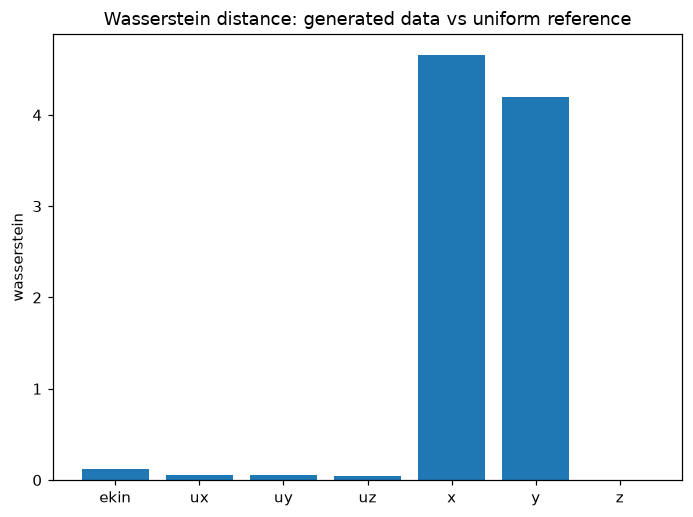

In [20]:
if run.result.comparisons:
    figure, ax = run.plot_metrics("wasserstein", comparison_index=-1)
    ax.set_title("Wasserstein distance: generated data vs uniform reference")
    plt.show()

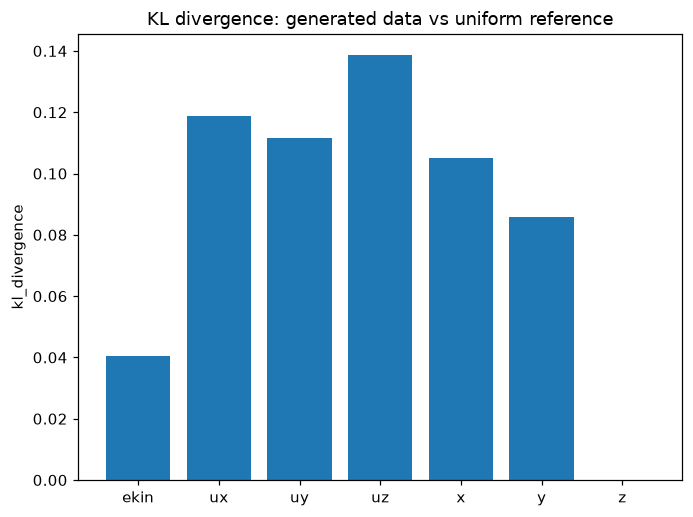

In [27]:
if run.result.comparisons:
    figure, ax = run.plot_metrics("kl_divergence", comparison_index=-1)
    ax.set_title("KL divergence: generated data vs uniform reference")
    plt.show()

## 7. Inspect stages and timings

Stage records include status, timestamps, duration, and an error field if a stage failed.

In [28]:
run.result.stages

{'fit': {'status': 'completed',
  'started_at': '2026-11-23T17:19:08.215168+00:00',
  'finished_at': '2026-11-23T17:19:09.020316+00:00',
  'duration_seconds': 0.8038826269985293},
 'resample': {'status': 'completed',
  'started_at': '2026-11-23T17:19:44.995685+00:00',
  'finished_at': '2026-11-23T17:19:45.187059+00:00',
  'duration_seconds': 0.18796113799908198},
 'compare_1': {'status': 'completed',
  'started_at': '2026-11-23T17:24:19.397481+00:00',
  'finished_at': '2026-11-23T17:24:29.801812+00:00',
  'duration_seconds': 10.402207443001316},
 'compare_2': {'status': 'completed',
  'started_at': '2026-11-23T17:29:18.349290+00:00',
  'finished_at': '2026-11-23T17:29:32.638283+00:00',
  'duration_seconds': 14.286788491999687}}

In [29]:
run.result.timings

{'fit': 0.8038826269985293,
 'resample': 0.18796113799908198,
 'compare_1': 10.402207443001316,
 'compare_2': 14.286788491999687}

In [30]:
run.status

'completed'

## 8. Reload the run manifest

`Run.load()` restores the run identity, paths, parameters, stages, timings, and comparison descriptors from `run.json`. Runtime-only objects are represented descriptively in the JSON metadata.

In [31]:
reloaded_run = Run.load(manifest)

{
    "id": reloaded_run.id,
    "name": reloaded_run.name,
    "status": reloaded_run.status,
    "fit_parameters": reloaded_run.fit_parameters,
    "model_path": str(reloaded_run.model_path),
    "generated_mcpl": str(reloaded_run.generated_mcpl_path),
}

{'id': 'e4fa1fb09b8744d8b9658435055b2eae',
 'name': 'kds-runs-resampled-showcase',
 'status': 'completed',
 'fit_parameters': {'J': 1, 'N': 10000, 'bw': 'knn', 'kernel': 'gaussian'},
 'model_path': '/home/jhonal/Brightify/runs/kds_runs_showcase/model.xml',
 'generated_mcpl': '/home/jhonal/Brightify/runs/kds_runs_showcase/generated.mcpl.gz'}

## 9. Use the convenience comparison function

`compare_runs(run, reference)` is equivalent to `run.compare_to(reference)`. The module returns a `ComparisonResult`, whose `metrics`, `columns`, and provenance are available directly.

In [33]:
if reloaded_run.result.generated_mcpl is not None:
    comparison = compare_runs(
        reloaded_run,
        UNIFORM_MCPL,
        columns=["ekin", "x", "y", "z", "ux", "uy", "uz"],
        scaling_factor=1.0,
        verbose=False,
    )
    print("Run:", comparison.run_id)
    print("Reference:", comparison.reference_path)
    print("Available metric groups:", sorted(comparison.metrics))

Run: e4fa1fb09b8744d8b9658435055b2eae
Reference: /home/jhonal/Brightify/examples/uniform/output.mcpl.gz
Available metric groups: ['multivariate', 'univariate']


## 10. Optional: inspect a small dataframe sample

Reading a file with `read_df_from_mcpl` is independent of `kds_runs`, but useful for a final sanity check of the generated and reference particle arrays.

In [38]:
columns = {"ekin", "x", "y", "z", "ux", "uy", "uz"}

generated_sample = read_df_from_mcpl(generated_mcpl, n=100, columns=columns)
generated_sample.head()

,ekin,x,y,z,ux,uy,uz
0,8.965342e-07,-36.190369,-15.529970,286.9151,-0.124899,-0.124634,0.984310
1,7.579919e-02,-6.230660,17.336958,286.9151,0.232443,0.487422,0.841659
2,3.112010e+00,-31.810204,6.478177,286.9151,0.235765,-0.384473,0.892522
3,7.835837e-01,22.357208,3.605886,286.9151,-0.538005,0.353482,0.765246
4,1.756140e-05,-50.004894,7.750439,286.9151,-0.783231,-0.022541,0.621322
